# Limpeza de sessões Intan a partir de um exemplo SPARQ

Você indica **os arquivos do rato** e **o `_clean.mat` de exemplo**. O notebook recupera o trecho de referência usado no exemplo, encontra o trecho equivalente em cada sessão, detecta o ruído com o algoritmo do SPARQ e salva o sinal limpo.

**Para usar:** edite só a célula 1 e rode tudo. Método, estrutura do Drive e limitações estão em [`docs/limpeza_intan.md`](docs/limpeza_intan.md).

## 1. Indique os arquivos

Em `arquivos`, use uma pasta, um `.int`, um padrão (`.../*T?_*.int`) ou uma lista. Use um exemplo da **mesma condição** dos arquivos. Se o `.int` do exemplo não for encontrado pela data e hora do nome, acrescente `'int_do_exemplo': <caminho>`.

In [1]:
from pathlib import Path
import os

BASE_DIR = Path(os.environ.get('BIOINFO_BASE_DIR', Path.cwd()))
DADOS    = BASE_DIR / 'dados_eletro'
EXEMPLOS = DADOS / 'exemplos_sparq'          # cópia da pasta SPARQ_results do Drive

RATO = 'R1'

LIMPEZAS = [
    {'arquivos': DADOS / RATO / 'NOR Registros',
     'exemplo':  EXEMPLOS / RATO / 'R1__norT4_240414_125924' / 'norT4_240414_125924_clean.mat'},
    {'arquivos': DADOS / RATO / '25% registros',
     'exemplo':  EXEMPLOS / RATO / 'R1__R1D25T4_240416_133540' / 'R1D25T4_240416_133540_clean.mat'},
    {'arquivos': DADOS / RATO / '50% registros',
     'exemplo':  EXEMPLOS / RATO / 'R1__R1D50T4_240418_122708' / 'R1D50T4_240418_122708_clean.mat'},
    {'arquivos': DADOS / RATO / '75% registros',
     'exemplo':  EXEMPLOS / RATO / 'R1__R1D75T4_240420_130736' / 'R1D75T4_240420_130736_clean.mat'},
]

# Sessões com falha anotada na planilha ficam de fora. Para incluir, liste o nome sem extensão.
INCLUIR_MESMO_COM_FALHA = [
    'R1 25% T3_240416_132016',   # arquivo de 214 s. O de 3,6 s (132013) continua fora
    'R1 25% T4_240416_133540',   # sessão do exemplo de 25% no Drive
]

LIMIAR_RUIDO = 0.50     # sessão descartada acima desta fração de ruído
SOBRESCREVER = False    # False retoma de onde parou
PLANILHA = DADOS / 'dados_sessões_comportamento_acontecimentos.xlsx'
SAIDA    = BASE_DIR / 'saida_limpeza_intan'

## 2. Preparação

In [2]:
import gc
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from tqdm.auto import tqdm

sys.path.insert(0, str(BASE_DIR))
from utils import limpeza_intan as li

pd.set_option('display.max_colwidth', 45, 'display.width', 200)
anotacoes = li.carregar_anotacoes(PLANILHA, RATO)

## 3. Sessões selecionadas

Regras do projeto: só testes (T), NOR apenas T1 a T3, sem sessões com falha anotada. Toda exclusão aparece com o motivo.

In [3]:
inventarios = [li.inventariar(l['arquivos'], anotacoes, INCLUIR_MESMO_COM_FALHA) for l in LIMPEZAS]
inventario = pd.concat(inventarios, ignore_index=True)
print(f"{len(inventario)} arquivos indicados, {int(inventario['selecionada'].sum())} selecionados")
display(inventario['motivo_exclusao'].replace('', 'selecionada').value_counts().to_frame('arquivos'))
display(inventario[inventario['trial'].fillna('').str.startswith('T')]
        [['stem', 'condicao', 'trial', 'duracao_s', 'anotacao', 'selecionada', 'motivo_exclusao']])

37 arquivos indicados, 15 selecionados


,arquivos
motivo_exclusao,
amostragem,19
selecionada,15
nome fora do padrão,1
NOR usa só T1 a T3,1
falha anotada,1


,stem,condicao,trial,duracao_s,anotacao,selecionada,motivo_exclusao
5,norT1_240414_121521,NOR,T1,73.5,Objeto caiu / sinal desconectou,True,
6,norT2_240414_122954,NOR,T2,208.3,,True,
7,norT3_240414_124446,NOR,T3,196.0,,True,
8,norT4_240414_125924,NOR,T4,188.2,,False,NOR usa só T1 a T3
13,r1 25% t1_240416_124853,0.25,T1,213.8,Sinal ruim,True,
14,R1 25% T2_240416_130351,0.25,T2,252.4,Sinal ruim,True,
15,R1 25% T3_240416_132013,0.25,T3,3.6,Arquivo extra / falha tentativa 3,False,falha anotada
16,R1 25% T3_240416_132016,0.25,T3,214.4,Arquivo extra / falha tentativa 3,True,
17,R1 25% T4_240416_133540,0.25,T4,181.4,Falha tentativa 4,True,
22,R1D50T1_240418_113900,0.5,T1,201.1,,True,


## 4. Referência de cada exemplo

O `_clean.mat` não guarda o trecho de referência. Ele é recuperado procurando a janela que faz o detector reproduzir a máscara. **Dice** mede a concordância com a máscara original (1 = idêntica).

In [4]:
exemplos = []
for l in tqdm(LIMPEZAS, desc='Exemplos'):
    exemplos.append(li.preparar_exemplo(l['exemplo'], l['arquivos'], l.get('int_do_exemplo')))

display(pd.DataFrame([{
    'exemplo': e['stem'], 'ruido_exemplo_%': round(100 * e['mascara'].mean(), 1),
    'referencia_ini_s': e['referencia']['ini'] / li.FS_LFP, 'referencia_fim_s': e['referencia']['fim'] / li.FS_LFP,
    'dice': round(e['referencia']['dice'], 4), 'amostras_iguais_%': round(100 * e['referencia']['concordancia'], 2),
} for e in exemplos]))

,exemplo,ruido_exemplo_%,referencia_ini_s,referencia_fim_s,dice,amostras_iguais_%
0,norT4_240414_125924,2.7,68.50,79.00,1.0000,100.00
1,R1D25T4_240416_133540,22.6,19.50,30.50,0.9939,99.72
2,R1D50T4_240418_122708,21.9,15.04,35.02,1.0000,100.00
3,R1D75T4_240420_130736,37.4,8.30,29.50,0.9935,99.51


## 5. Limpeza

Cada sessão vai para `saida_limpeza_intan/<rato>/<condição>/<rato>__<sessão>/` com `_downsample.npy` (16 canais × amostras, 1 kHz, ruído = `NaN`), `_noise_mask.npy` e `_downsample.json`. A sessão do próprio exemplo mantém a máscara original.

In [5]:
relatorio, mascaras = [], {}
for inv, exemplo in zip(inventarios, exemplos):
    for _, linha in tqdm(list(inv[inv['selecionada']].iterrows()), desc=exemplo['stem']):
        try:
            res, mascara = li.limpar_sessao(linha, exemplo, RATO, SAIDA, limiar_ruido=LIMIAR_RUIDO,
                                            sobrescrever=SOBRESCREVER)
            mascaras[linha['stem']] = mascara
        except Exception as erro:
            res = {'stem': linha['stem'], 'condicao': linha['condicao'], 'trial': linha['trial'],
                   'status': 'ERRO', 'motivo': str(erro)}
        relatorio.append(res)
        gc.collect()

df_relatorio = pd.DataFrame(relatorio)
(SAIDA / RATO).mkdir(parents=True, exist_ok=True)
df_relatorio.to_csv(SAIDA / RATO / 'relatorio_limpeza.csv', index=False, encoding='utf-8-sig')
print(df_relatorio['status'].value_counts().to_string())
tabela = df_relatorio.assign(ruido_pct=(100 * df_relatorio['frac_ruido']).round(1))
display(tabela[['stem', 'condicao', 'trial', 'status', 'ruido_pct', 'origem_mascara', 'referencia_s']])

status
JA_EXISTE    13
OK            2


,stem,condicao,trial,status,ruido_pct,origem_mascara,referencia_s
0,norT1_240414_121521,NOR,T1,JA_EXISTE,42.4,referência pareada,"[31.0, 41.5]"
1,norT2_240414_122954,NOR,T2,JA_EXISTE,2.9,referência pareada,"[142.0, 152.5]"
2,norT3_240414_124446,NOR,T3,JA_EXISTE,3.8,referência pareada,"[42.0, 52.5]"
3,r1 25% t1_240416_124853,0.25,T1,JA_EXISTE,17.2,referência pareada,"[21.0, 32.0]"
4,R1 25% T2_240416_130351,0.25,T2,JA_EXISTE,5.1,referência pareada,"[63.0, 74.0]"
5,R1 25% T3_240416_132016,0.25,T3,OK,8.3,referência pareada,"[61.0, 72.0]"
6,R1 25% T4_240416_133540,0.25,T4,OK,22.6,exemplo (marcação original),"[19.5, 30.5]"
7,R1D50T1_240418_113900,0.5,T1,JA_EXISTE,6.7,referência pareada,"[138.0, 157.98]"
8,R1D50T2_240418_115409,0.5,T2,JA_EXISTE,2.8,referência pareada,"[39.0, 58.98]"
9,R1D50T3_240418_120842,0.5,T3,JA_EXISTE,2.7,referência pareada,"[113.0, 132.98]"


## 6. Conferência visual

Cada linha é uma sessão. Confira principalmente sessões com muito ruído ou com a referência encostada em um bloco de ruído.

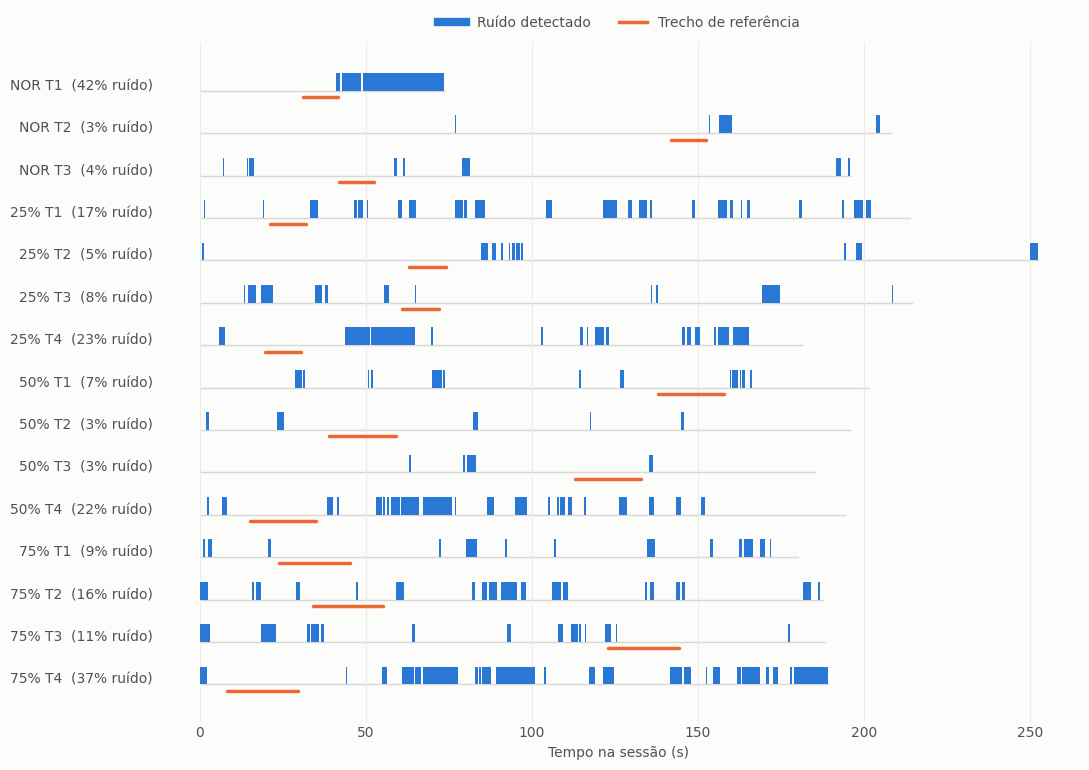

In [6]:
COR_RUIDO, COR_REF = '#2a78d6', '#eb6834'
ok = df_relatorio[df_relatorio['status'].isin(['OK', 'JA_EXISTE', 'DESCARTADO'])].reset_index(drop=True)

fig, ax = plt.subplots(figsize=(11, 0.42 * len(ok) + 1.5), facecolor='#fcfcfb')
ax.set_facecolor('#fcfcfb')
for i, s in ok.iterrows():
    m = mascaras[s['stem']]
    bordas = np.diff(np.r_[0, m.astype(np.int8), 0])
    ini, fim = np.flatnonzero(bordas == 1), np.flatnonzero(bordas == -1)
    ax.broken_barh(list(zip(ini / 1000, (fim - ini) / 1000)), (i - 0.28, 0.42), color=COR_RUIDO, linewidth=0)
    ax.plot([0, m.size / 1000], [i + 0.14] * 2, color='#d8d7d2', lw=1, zorder=0)
    ax.plot(s['referencia_s'], [i + 0.29] * 2, color=COR_REF, lw=2.5, solid_capstyle='round')
rotulo = {'0.25': '25%', '0.5': '50%', '0.75': '75%', 'NOR': 'NOR'}
ax.set_yticks(range(len(ok)), [f"{rotulo[c]} {t}  ({100 * r:.0f}% ruído)"
                               for c, t, r in zip(ok['condicao'], ok['trial'], ok['frac_ruido'])], color='#52514e')
ax.invert_yaxis()
ax.set_xlabel('Tempo na sessão (s)', color='#52514e')
ax.tick_params(colors='#52514e', length=0)
ax.grid(axis='x', color='#ecebe6', lw=0.8)
ax.set_axisbelow(True)
for lado in ax.spines.values():
    lado.set_visible(False)
ax.plot([], [], color=COR_RUIDO, lw=6, label='Ruído detectado')
ax.plot([], [], color=COR_REF, lw=2.5, label='Trecho de referência')
ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False, labelcolor='#52514e')
fig.tight_layout()
fig.savefig(SAIDA / RATO / 'mascaras_limpeza.png', dpi=140)
plt.show()

## 7. Validação cruzada entre exemplos

A referência de um exemplo prevê a máscara de **outro** exemplo, que o método não viu. É um teste mais difícil que o uso normal, porque compara dias diferentes. As colunas comparam o método usado (`pareada`) com copiar os limiares e com o critério de `sparq_auto.m`.

In [7]:
if len(exemplos) >= 2:
    cv = li.validacao_cruzada(exemplos)
    cv.to_csv(SAIDA / RATO / 'validacao_cruzada.csv', index=False, encoding='utf-8-sig')
    display(cv[['pareada', 'limiar_copiado', 'sparq_auto']].agg(['median', 'mean', 'min', 'max']).round(3))
    display(cv.round(3))
else:
    print('Indique ao menos dois exemplos para a validação cruzada.')

,pareada,limiar_copiado,sparq_auto
median,0.928,0.700,0.807
mean,0.909,0.720,0.758
min,0.850,0.544,0.490
max,0.963,0.963,0.928


,fonte,alvo,pareada,limiar_copiado,sparq_auto
0,norT4_240414_125924,R1D25T4_240416_133540,0.937,0.963,0.715
1,norT4_240414_125924,R1D50T4_240418_122708,0.928,0.883,0.898
2,norT4_240414_125924,R1D75T4_240420_130736,0.929,0.544,0.928
3,R1D25T4_240416_133540,norT4_240414_125924,0.863,0.578,0.490
4,R1D25T4_240416_133540,R1D50T4_240418_122708,0.929,0.886,0.898
5,R1D25T4_240416_133540,R1D75T4_240420_130736,0.963,0.544,0.928
6,R1D50T4_240418_122708,norT4_240414_125924,0.861,0.620,0.490
7,R1D50T4_240418_122708,R1D25T4_240416_133540,0.930,0.881,0.715
8,R1D50T4_240418_122708,R1D75T4_240420_130736,0.941,0.544,0.928
9,R1D75T4_240420_130736,norT4_240414_125924,0.850,0.592,0.490
